In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)

In [28]:
df = pd.read_csv('data.csv', parse_dates=['Date'])
df = df.rename(columns={'Product_Name_y': 'Product_Name', 'Category_y': 'Category', 'City_y': 'City'})
print(df.shape)

(814912, 33)


In [29]:
display(df.head())
df.info()

,Transaction_ID,Customer_ID,Date,Product_ID,Quantity,Unit_Price,Discount,Store_Name,Channel,Age_Group,Gender,Birth_Year,Join_Date,Loyalty_Member,Preferred_Payment,...,Brand,Unit,Is_Perishable,Cost_Estimated,Recency,Frequency,Monetary,Cluster,Segment,Store_ID,City,Area,Region,Size_Class,Opening_Date
0,T000001,C00112,2024-01-01,P117,1,70.0,0.0,Cairo - New Cairo,In-Store,18-24,Male,1985,2024-08-09,Yes,Credit Card,...,Baraka,250g,False,False,4.158883,3.218876,8.218582,6,Loyal Customers,S04,Cairo,New Cairo,Greater Cairo,Large,2021-02-25
1,T000001,C00112,2024-01-01,P114,1,30.0,0.0,Cairo - New Cairo,In-Store,18-24,Male,1985,2024-08-09,Yes,Credit Card,...,Al Waha,1kg,False,False,4.158883,3.218876,8.218582,6,Loyal Customers,S04,Cairo,New Cairo,Greater Cairo,Large,2021-02-25
2,T000001,C00112,2024-01-01,P125,4,28.0,0.0,Cairo - New Cairo,In-Store,18-24,Male,1985,2024-08-09,Yes,Credit Card,...,Nile Select,400g,True,False,4.158883,3.218876,8.218582,6,Loyal Customers,S04,Cairo,New Cairo,Greater Cairo,Large,2021-02-25
3,T000001,C00112,2024-01-01,P062,3,55.0,0.0,Cairo - New Cairo,In-Store,18-24,Male,1985,2024-08-09,Yes,Credit Card,...,Baraka,each,False,False,4.158883,3.218876,8.218582,6,Loyal Customers,S04,Cairo,New Cairo,Greater Cairo,Large,2021-02-25
4,T000001,C00112,2024-01-01,P085,2,24.0,0.0,Cairo - New Cairo,In-Store,18-24,Male,1985,2024-08-09,Yes,Credit Card,...,Nile Select,1kg,True,False,4.158883,3.218876,8.218582,6,Loyal Customers,S04,Cairo,New Cairo,Greater Cairo,Large,2021-02-25


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 814912 entries, 0 to 814911
Data columns (total 33 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   Transaction_ID     814912 non-null  object        
 1   Customer_ID        814912 non-null  object        
 2   Date               814912 non-null  datetime64[ns]
 3   Product_ID         814912 non-null  object        
 4   Quantity           814912 non-null  int64         
 5   Unit_Price         814912 non-null  float64       
 6   Discount           814912 non-null  float64       
 7   Store_Name         814912 non-null  object        
 8   Channel            814912 non-null  object        
 9   Age_Group          814912 non-null  object        
 10  Gender             814912 non-null  object        
 11  Birth_Year         814912 non-null  int64         
 12  Join_Date          814912 non-null  object        
 13  Loyalty_Member     814912 non-null  object  

In [30]:
print(df.isna().sum()[df.isna().sum() > 0])
print(df.duplicated(['Transaction_ID', 'Product_ID']).sum())
print(df['Customer_ID'].nunique(), df['Transaction_ID'].nunique())

Store_ID        2
City            2
Area            2
Region          2
Size_Class      2
Opening_Date    2
dtype: int64
2439
7000 136437


In [31]:
df['Gross'] = df['Quantity'] * df['Unit_Price']
df['Discount_Amt'] = df['Gross'] * df['Discount']
df['Revenue'] = df['Gross'] - df['Discount_Amt']
df['Cost'] = df['Quantity'] * df['Cost_Price']
df['Profit'] = df['Revenue'] - df['Cost']
df['YM'] = df['Date'].dt.to_period('M')
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month

In [32]:
first = df.drop_duplicates('Customer_ID').set_index('Customer_ID')
cust = first[['Cluster', 'Segment', 'Age_Group', 'Gender', 'Loyalty_Member', 'Preferred_Payment']].copy()
cust['Recency'] = np.expm1(first['Recency']).round()
cust['Frequency'] = np.expm1(first['Frequency']).round()
cust['Revenue'] = df.groupby('Customer_ID')['Revenue'].sum()
cust['Profit'] = df.groupby('Customer_ID')['Profit'].sum()
cust['Invoices'] = df.groupby('Customer_ID')['Transaction_ID'].nunique()
cust['AvgInvoice'] = cust['Revenue'] / cust['Invoices']
print((cust['Frequency'] == cust['Invoices']).mean())
cust.head()

1.0


,Cluster,Segment,Age_Group,Gender,Loyalty_Member,Preferred_Payment,Recency,Frequency,Revenue,Profit,Invoices,AvgInvoice
Customer_ID,,,,,,,,,,,,
C00112,6,Loyal Customers,18-24,Male,Yes,Credit Card,63.0,24.0,8204.5390,2154.2990,24,341.855792
C00167,1,Valuable Customers,55+,Female,Yes,Credit Card,5.0,34.0,14534.4275,3859.7475,34,427.483162
C00168,2,At Risk Customers,45-54,Female,Yes,Cash,545.0,13.0,4734.3820,1222.9320,13,364.183231
C00173,7,Potential Loyal Customers,25-34,Female,No,Credit Card,53.0,11.0,3650.4950,1150.8750,11,331.863182
C00258,3,Champions,35-44,Female,Yes,Cash,4.0,77.0,69498.1705,18948.0505,77,902.573643


In [33]:
inv = df.groupby('Transaction_ID').agg(Customer_ID=('Customer_ID', 'first'), Segment=('Segment', 'first'), Date=('Date', 'first'), Store=('Store_Name', 'first'), Channel=('Channel', 'first'),
                                       Region=('Region', 'first'), Size_Class=('Size_Class', 'first'), Revenue=('Revenue', 'sum'),
                                       Items=('Quantity', 'sum'), Lines=('Product_ID', 'size'))
inv.head()

,Customer_ID,Segment,Date,Store,Channel,Region,Size_Class,Revenue,Items,Lines
Transaction_ID,,,,,,,,,,
T000001,C00112,Loyal Customers,2024-01-01,Cairo - New Cairo,In-Store,Greater Cairo,Large,528.0,13,7
T000002,C00167,Valuable Customers,2024-01-01,Giza - Haram,In-Store,Greater Cairo,Medium,135.0,4,4
T000003,C00168,At Risk Customers,2024-01-01,Assiut - Downtown,In-Store,Upper Egypt,Medium,263.4,7,4
T000004,C00173,Potential Loyal Customers,2024-01-01,Alexandria - Montaza,Delivery,Alexandria,Medium,166.0,4,3
T000005,C00258,Champions,2024-01-01,Alexandria - Sidi Gaber,In-Store,Alexandria,Medium,616.0,16,6


Segment
Loyal Customers              1335
Valuable Customers           1049
At Risk Customers            1026
Potential Loyal Customers     979
Hibernating Customers         864
Champions                     764
Recent High Spenders          700
Lost Customers                283
dtype: int64

Segment
Loyal Customers              19.1
Valuable Customers           15.0
At Risk Customers            14.7
Potential Loyal Customers    14.0
Hibernating Customers        12.3
Champions                    10.9
Recent High Spenders         10.0
Lost Customers                4.0
dtype: float64

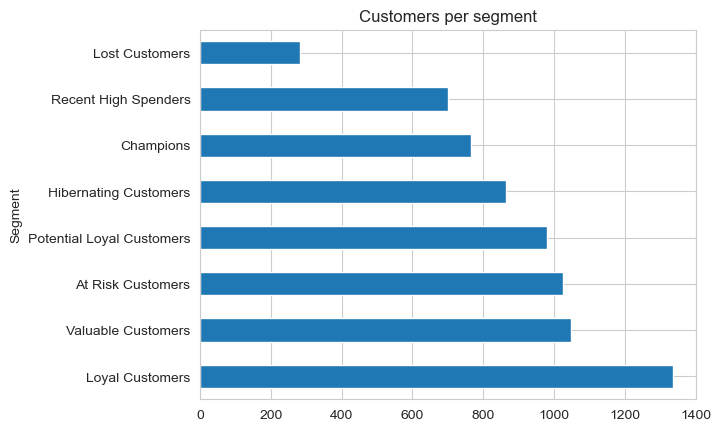

In [34]:
seg = cust.groupby('Segment').size().sort_values(ascending=False)
display(seg)
display((seg / seg.sum() * 100).round(1))
seg.plot.barh(title='Customers per segment')
plt.show()

In [35]:
prof = cust.groupby('Segment')[['Recency', 'Frequency', 'Revenue', 'AvgInvoice']].median().round(0)
prof['Customers'] = seg
prof = prof.sort_values('Revenue', ascending=False)
order = prof.index.tolist()
prof

,Recency,Frequency,Revenue,AvgInvoice,Customers
Segment,,,,,
Champions,7.0,55.0,48520.0,869.0,764
Valuable Customers,6.0,26.0,10664.0,421.0,1049
Loyal Customers,32.0,25.0,10406.0,423.0,1335
Potential Loyal Customers,47.0,11.0,3913.0,368.0,979
At Risk Customers,461.0,10.0,3549.0,353.0,1026
Recent High Spenders,10.0,8.0,2745.0,343.0,700
Hibernating Customers,125.0,5.0,1775.0,326.0,864
Lost Customers,303.0,2.0,585.0,292.0,283


In [36]:
rev = df.groupby('Segment')[['Revenue', 'Profit']].sum().reindex(order)
rev['Customers %'] = seg.reindex(order) / seg.sum() * 100
rev['Revenue %'] = rev['Revenue'] / rev['Revenue'].sum() * 100
rev['Margin %'] = rev['Profit'] / rev['Revenue'] * 100
rev.round(1)

,Revenue,Profit,Customers %,Revenue %,Margin %
Segment,,,,,
Champions,36832100.3,10139331.4,10.9,49.0,27.5
Valuable Customers,11636110.4,2997611.9,15.0,15.5,25.8
Loyal Customers,15065480.7,3862223.1,19.1,20.0,25.6
Potential Loyal Customers,4047790.6,1077427.5,14.0,5.4,26.6
At Risk Customers,3786858.5,966096.4,14.7,5.0,25.5
Recent High Spenders,2008170.1,572890.1,10.0,2.7,28.5
Hibernating Customers,1595524.9,439663.6,12.3,2.1,27.6
Lost Customers,170548.2,46941.5,4.0,0.2,27.5


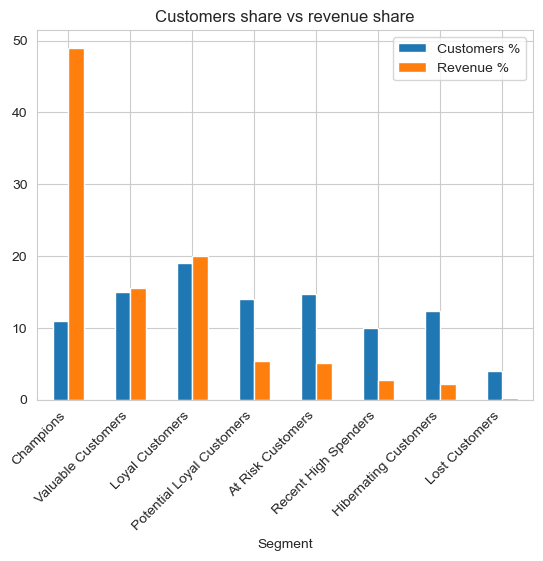

In [37]:
rev[['Customers %', 'Revenue %']].plot.bar(title='Customers share vs revenue share')
plt.xticks(rotation=45, ha='right')
plt.show()

In [38]:
top20 = cust['Revenue'].sort_values(ascending=False).head(int(len(cust) * 0.2))
print('top 20% customers revenue share:', round(top20.sum() / cust['Revenue'].sum(), 3))
(cust.loc[top20.index, 'Segment'].value_counts(normalize=True) * 100).round(1)

top 20% customers revenue share: 0.627


Segment
Champions             54.6
Loyal Customers       24.6
Valuable Customers    20.8
Name: proportion, dtype: float64

In [39]:
monetary_check = np.expm1(first['Monetary']).corr(cust['Revenue'])
print('Monetary in data vs real revenue:', round(monetary_check, 3))
print(round(np.expm1(first['Monetary']).mean()), round(cust['Revenue'].mean()))

Monetary in data vs real revenue: 0.975
4005 10735


In [40]:
inv.groupby('Segment')[['Revenue', 'Items', 'Lines']].mean().round(1).reindex(order)

,Revenue,Items,Lines
Segment,,,
Champions,852.0,20.0,7.0
Valuable Customers,435.8,9.9,5.8
Loyal Customers,444.1,10.1,5.9
Potential Loyal Customers,374.4,8.3,5.0
At Risk Customers,356.0,7.9,4.8
Recent High Spenders,347.3,7.6,4.6
Hibernating Customers,332.3,7.3,4.5
Lost Customers,308.4,7.1,4.3


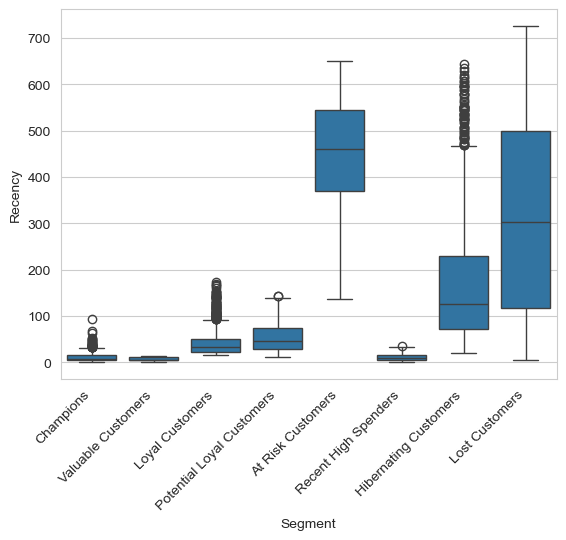

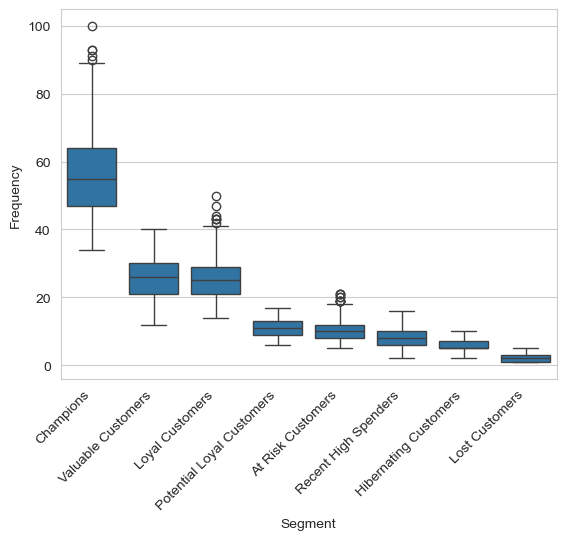

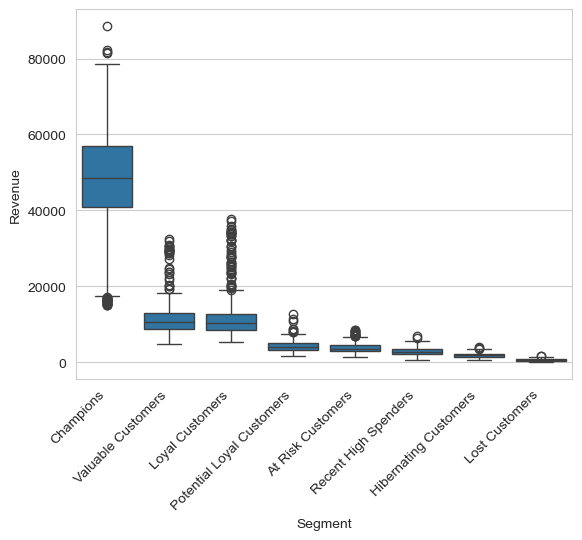

In [41]:
sns.boxplot(data=cust, x='Segment', y='Recency', order=order)
plt.xticks(rotation=45, ha='right')
plt.show()
sns.boxplot(data=cust, x='Segment', y='Frequency', order=order)
plt.xticks(rotation=45, ha='right')
plt.show()
sns.boxplot(data=cust, x='Segment', y='Revenue', order=order)
plt.xticks(rotation=45, ha='right')
plt.show()

Year,2024,2025,Change %
Segment,,,
Champions,17840512.0,18991588.0,6.0
Valuable Customers,5503026.0,6133084.0,11.0
Loyal Customers,7464701.0,7600779.0,2.0
Potential Loyal Customers,1809301.0,2238489.0,24.0
At Risk Customers,3506519.0,280339.0,-92.0
Recent High Spenders,607587.0,1400583.0,131.0
Hibernating Customers,853124.0,742401.0,-13.0
Lost Customers,102043.0,68505.0,-33.0


Year,2024,2025
Segment,,
Champions,764,764
Valuable Customers,1046,1049
Loyal Customers,1335,1335
Potential Loyal Customers,911,979
At Risk Customers,1026,248
Recent High Spenders,506,700
Hibernating Customers,801,741
Lost Customers,208,164


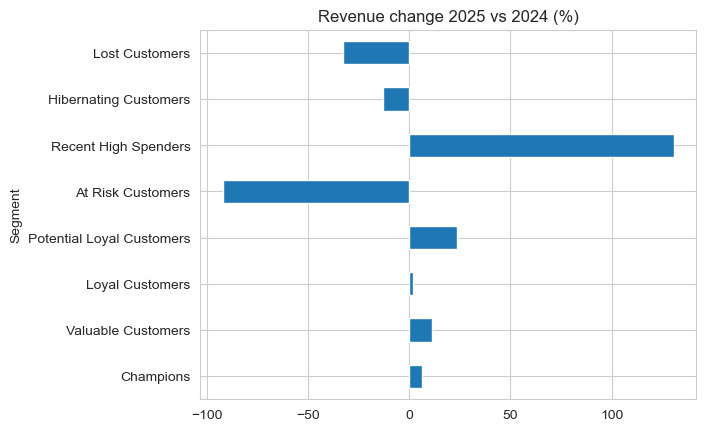

In [42]:
year = df.pivot_table(index='Segment', columns='Year', values='Revenue', aggfunc='sum').reindex(order)
year['Change %'] = (year[2025] / year[2024] - 1) * 100
display(year.round(0))
display(df.groupby(['Segment', 'Year'])['Customer_ID'].nunique().unstack().reindex(order))
year['Change %'].plot.barh(title='Revenue change 2025 vs 2024 (%)')
plt.show()

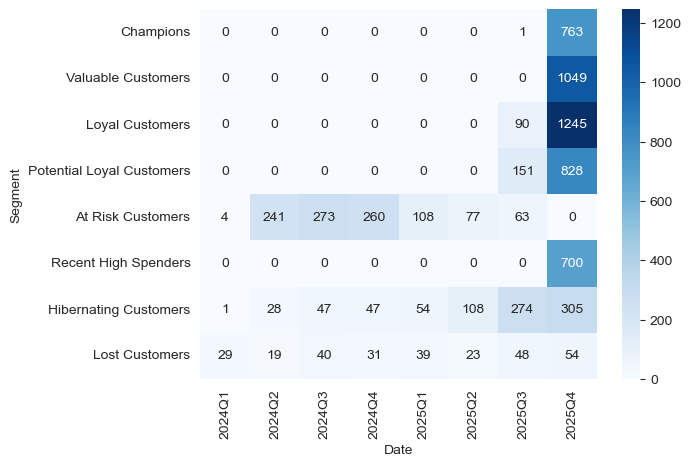

Segment
Champions                      0.1
Valuable Customers             0.0
Loyal Customers                7.0
Potential Loyal Customers     15.9
At Risk Customers            100.0
Recent High Spenders           0.0
Hibernating Customers         65.0
Lost Customers                80.9
Name: Inactive, dtype: float64

In [43]:
last = df.groupby('Customer_ID')['Date'].max().dt.to_period('Q')
last_q = pd.crosstab(cust['Segment'], last.reindex(cust.index)).reindex(order)
sns.heatmap(last_q, annot=True, fmt='d', cmap='Blues')
plt.show()
(cust.assign(Inactive=cust['Recency'] > 90).groupby('Segment')['Inactive'].mean() * 100).round(1).reindex(order)

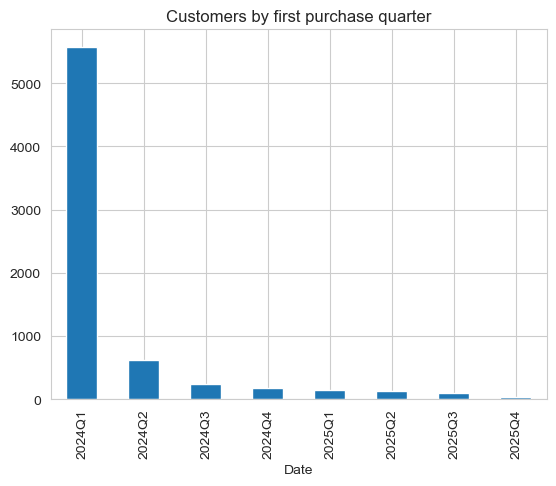

In [44]:
first_q = df.groupby('Customer_ID')['Date'].min().dt.to_period('Q')
first_q.value_counts().sort_index().plot.bar(title='Customers by first purchase quarter')
plt.show()

In [45]:
variety = df.groupby('Customer_ID')['Product_ID'].nunique()
display(variety.groupby(cust['Segment']).mean().round(1).reindex(order))
inv_sorted = inv.sort_values(['Customer_ID', 'Date'])
gap = inv_sorted.groupby('Customer_ID')['Date'].diff().dt.days
gap.groupby(inv_sorted['Segment']).median().reindex(order)

Segment
Champions                    122.1
Valuable Customers            83.8
Loyal Customers               83.9
Potential Loyal Customers     42.8
At Risk Customers             39.4
Recent High Spenders          31.8
Hibernating Customers         22.1
Lost Customers                 8.1
Name: Product_ID, dtype: float64

Segment
Champions                      8.0
Valuable Customers            19.0
Loyal Customers               18.0
Potential Loyal Customers     40.0
At Risk Customers             17.0
Recent High Spenders          42.0
Hibernating Customers         65.0
Lost Customers               124.5
Name: Date, dtype: float64

In [46]:
for col in ['Gender', 'Age_Group', 'Loyalty_Member', 'Preferred_Payment']:
    display((pd.crosstab(cust['Segment'], cust[col], normalize='index') * 100).round(1).reindex(order))

Gender,Female,Male,Unknown
Segment,,,
Champions,51.2,47.3,1.6
Valuable Customers,50.1,49.2,0.7
Loyal Customers,54.8,44.0,1.2
Potential Loyal Customers,52.4,46.1,1.5
At Risk Customers,54.4,44.6,1.0
Recent High Spenders,52.4,47.0,0.6
Hibernating Customers,50.7,47.5,1.9
Lost Customers,58.0,41.0,1.1


Age_Group,18-24,25-34,35-44,45-54,55+
Segment,,,,,
Champions,9.9,31.9,30.2,17.8,10.1
Valuable Customers,13.2,31.3,26.2,17.5,11.8
Loyal Customers,13.0,29.8,28.8,16.6,11.8
Potential Loyal Customers,11.4,33.0,27.3,17.1,11.2
At Risk Customers,12.6,30.0,27.1,19.3,11.0
Recent High Spenders,12.6,32.0,28.1,17.0,10.3
Hibernating Customers,12.5,32.2,25.9,16.7,12.7
Lost Customers,10.2,25.8,33.9,20.8,9.2


Loyalty_Member,No,Yes
Segment,,
Champions,17.7,82.3
Valuable Customers,32.0,68.0
Loyal Customers,29.8,70.2
Potential Loyal Customers,67.9,32.1
At Risk Customers,72.4,27.6
Recent High Spenders,74.1,25.9
Hibernating Customers,75.3,24.7
Lost Customers,78.4,21.6


Preferred_Payment,Cash,Credit Card,Mobile Wallet
Segment,,,
Champions,57.3,27.0,15.7
Valuable Customers,53.8,32.8,13.4
Loyal Customers,55.1,30.6,14.3
Potential Loyal Customers,55.9,29.5,14.6
At Risk Customers,54.2,29.1,16.7
Recent High Spenders,53.9,30.4,15.7
Hibernating Customers,55.7,30.1,14.2
Lost Customers,51.9,32.5,15.5


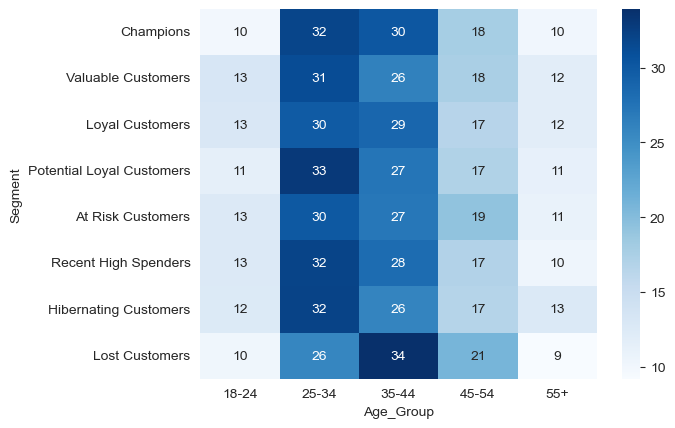

In [47]:
age = pd.crosstab(cust['Segment'], cust['Age_Group'], normalize='index').reindex(order) * 100
sns.heatmap(age, annot=True, fmt='.0f', cmap='Blues')
plt.show()

In [48]:
display((pd.crosstab(inv['Segment'], inv['Channel'], normalize='index') * 100).round(1).reindex(order))
display((pd.crosstab(inv['Segment'], inv['Region'], normalize='index') * 100).round(1).reindex(order))
(pd.crosstab(inv['Segment'], inv['Size_Class'], normalize='index') * 100).round(1).reindex(order)

Channel,Delivery,In-Store,Online Pickup
Segment,,,
Champions,10.1,84.9,5.0
Valuable Customers,10.1,85.0,4.9
Loyal Customers,10.0,85.0,5.0
Potential Loyal Customers,9.8,85.1,5.1
At Risk Customers,10.1,84.8,5.0
Recent High Spenders,10.1,85.2,4.7
Hibernating Customers,11.2,83.7,5.1
Lost Customers,11.6,83.5,4.9


Region,Alexandria,Canal,Delta,Greater Cairo,Red Sea,Upper Egypt
Segment,,,,,,
Champions,14.0,8.9,15.7,45.6,3.0,12.8
Valuable Customers,13.8,10.5,15.0,41.6,2.9,16.1
Loyal Customers,14.6,10.1,14.9,43.8,2.4,14.2
Potential Loyal Customers,13.3,9.6,15.0,47.5,3.0,11.7
At Risk Customers,15.5,9.8,13.8,44.8,3.2,12.9
Recent High Spenders,12.2,10.5,16.5,42.0,3.2,15.7
Hibernating Customers,15.5,9.0,14.2,43.1,2.4,16.0
Lost Customers,16.1,10.7,14.8,41.2,4.9,12.3


Size_Class,Large,Medium,Small
Segment,,,
Champions,26.9,45.7,27.4
Valuable Customers,28.0,43.8,28.3
Loyal Customers,30.9,44.4,24.8
Potential Loyal Customers,30.9,46.0,23.1
At Risk Customers,31.4,44.1,24.5
Recent High Spenders,28.5,41.7,29.8
Hibernating Customers,28.2,48.5,23.3
Lost Customers,31.6,41.6,26.8


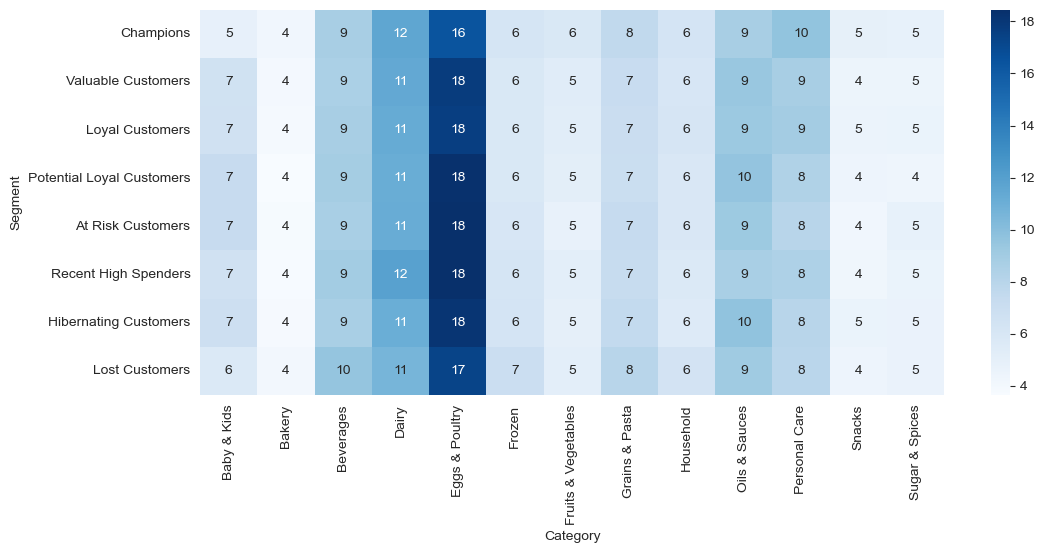

In [49]:
cat = df.pivot_table(index='Segment', columns='Category', values='Revenue', aggfunc='sum').reindex(order)
cat = cat.div(cat.sum(axis=1), axis=0) * 100
plt.figure(figsize=(12, 5))
sns.heatmap(cat, annot=True, fmt='.0f', cmap='Blues')
plt.show()

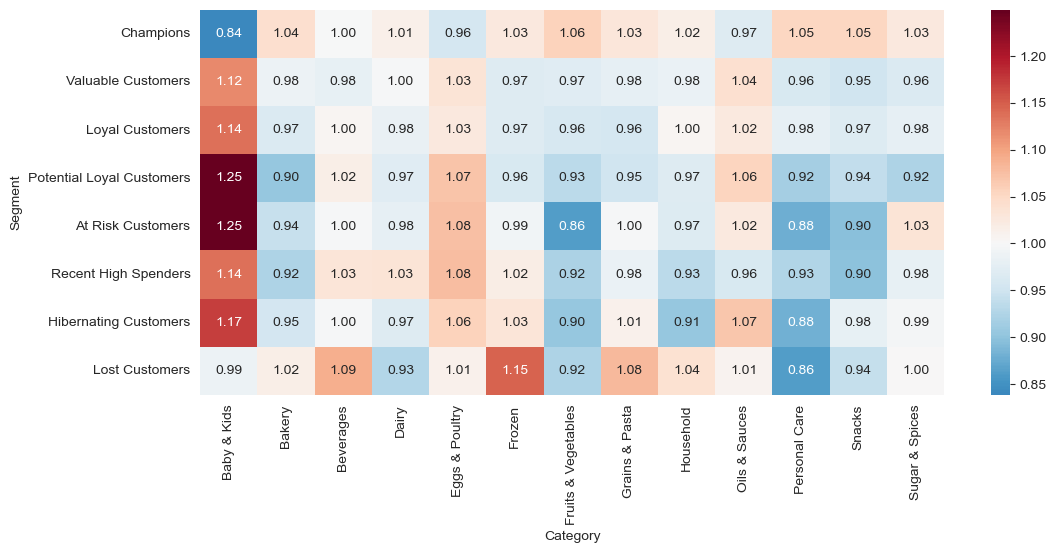

In [50]:
overall = df.groupby('Category')['Revenue'].sum() / df['Revenue'].sum() * 100
plt.figure(figsize=(12, 5))
sns.heatmap(cat / overall, annot=True, fmt='.2f', cmap='RdBu_r', center=1)
plt.show()

In [51]:
disc = df.groupby('Segment')[['Discount_Amt', 'Gross']].sum()
print((disc['Discount_Amt'] / disc['Gross'] * 100).round(2).reindex(order))
print((df.assign(has=df['Discount'] > 0).groupby('Segment')['has'].mean() * 100).round(1).reindex(order))

Segment
Champions                    2.73
Valuable Customers           4.67
Loyal Customers              4.60
Potential Loyal Customers    3.49
At Risk Customers            1.46
Recent High Spenders         2.22
Hibernating Customers        1.53
Lost Customers               1.52
dtype: float64
Segment
Champions                    15.9
Valuable Customers           26.9
Loyal Customers              27.0
Potential Loyal Customers    20.6
At Risk Customers             8.7
Recent High Spenders         13.1
Hibernating Customers         9.1
Lost Customers                9.5
Name: has, dtype: float64


In [52]:
per = df.groupby(['Segment', 'Is_Perishable'])['Revenue'].sum().unstack()
(per[True] / per.sum(axis=1) * 100).round(1).reindex(order)

Segment
Champions                    44.3
Valuable Customers           44.4
Loyal Customers              44.0
Potential Loyal Customers    44.1
At Risk Customers            44.3
Recent High Spenders         45.4
Hibernating Customers        44.4
Lost Customers               44.2
dtype: float64

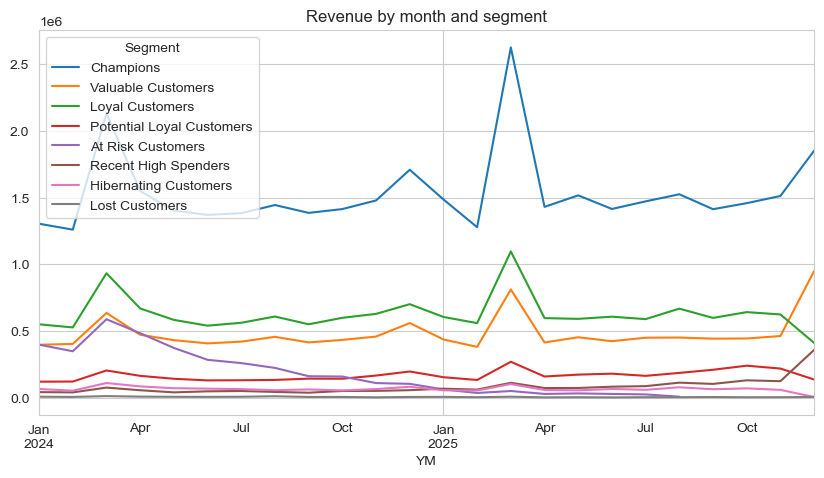

In [53]:
df.pivot_table(index='YM', columns='Segment', values='Revenue', aggfunc='sum')[order].plot(figsize=(10, 5), title='Revenue by month and segment')
plt.show()

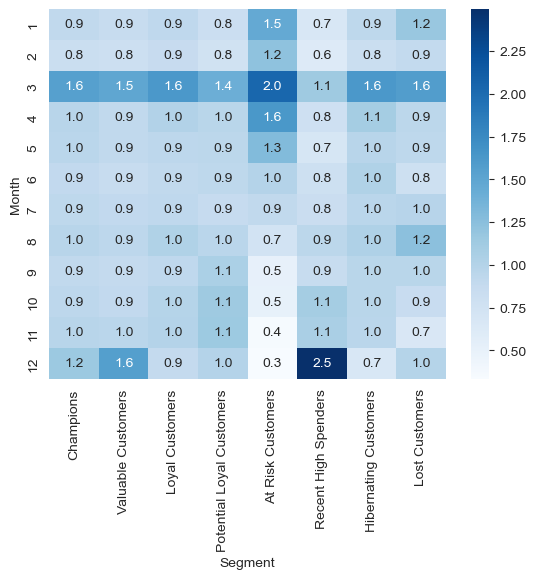

In [54]:
month = df.pivot_table(index='Month', columns='Segment', values='Revenue', aggfunc='sum')[order]
sns.heatmap(month / month.mean(), annot=True, fmt='.1f', cmap='Blues')
plt.show()

In [55]:
display(cust.groupby('Loyalty_Member')[['Frequency', 'Revenue', 'AvgInvoice']].mean().round(1))
cust.groupby(['Segment', 'Loyalty_Member'])['Revenue'].mean().unstack().round(0).reindex(order)

,Frequency,Revenue,AvgInvoice
Loyalty_Member,,,
No,13.2,6084.7,384.9
Yes,26.4,15856.4,490.9


Loyalty_Member,No,Yes
Segment,,
Champions,48700.0,48104.0
Valuable Customers,10189.0,11518.0
Loyal Customers,10338.0,11687.0
Potential Loyal Customers,4002.0,4415.0
At Risk Customers,3691.0,3690.0
Recent High Spenders,2817.0,3017.0
Hibernating Customers,1864.0,1794.0
Lost Customers,599.0,617.0


In [56]:
display(df.assign(Has_Discount=df['Discount'] > 0).groupby('Has_Discount')['Quantity'].mean().round(2))
inv['Has_Discount'] = inv.index.isin(df.loc[df['Discount'] > 0, 'Transaction_ID'])
inv.groupby('Has_Discount')[['Revenue', 'Items', 'Lines']].mean().round(1)

Has_Discount
False    2.15
True     2.01
Name: Quantity, dtype: float64

,Revenue,Items,Lines
Has_Discount,,,
False,475.8,10.5,5.1
True,600.2,14.1,6.5


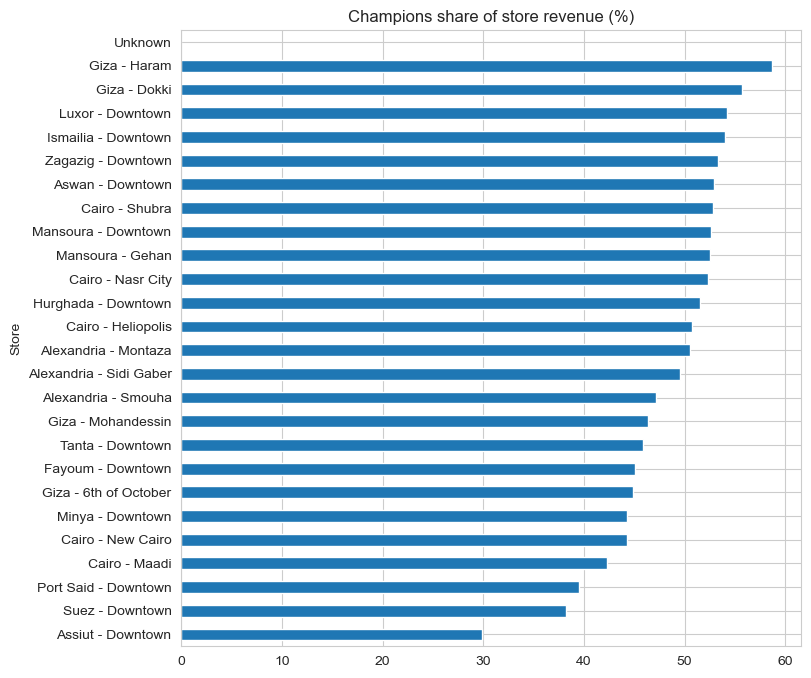

In [57]:
store = inv.groupby(['Store', 'Segment'])['Revenue'].sum().unstack()
store = store.div(store.sum(axis=1), axis=0) * 100
store['Champions'].sort_values().plot.barh(figsize=(8, 8), title='Champions share of store revenue (%)')
plt.show()

In [58]:
top = df.groupby(['Segment', 'Product_Name'])['Revenue'].sum().reset_index()
top = top.sort_values(['Segment', 'Revenue'], ascending=[True, False]).groupby('Segment').head(3)
top.groupby('Segment')['Product_Name'].apply(list).reindex(order)

Segment
Champions                       [Chicken 1kg, Coffee 200g, Eggs 12pc]
Valuable Customers              [Chicken 1kg, Coffee 200g, Eggs 12pc]
Loyal Customers              [Chicken 1kg, Coffee 200g, Diapers Pack]
Potential Loyal Customers      [Chicken 1kg, Diapers Pack, Eggs 12pc]
At Risk Customers              [Chicken 1kg, Diapers Pack, Eggs 12pc]
Recent High Spenders            [Chicken 1kg, Eggs 12pc, Coffee 200g]
Hibernating Customers           [Chicken 1kg, Eggs 12pc, Coffee 200g]
Lost Customers                  [Chicken 1kg, Coffee 200g, Eggs 12pc]
Name: Product_Name, dtype: object

In [59]:
summary = prof.join(rev[['Revenue', 'Revenue %', 'Margin %']], rsuffix='_total')
summary.round(1).to_csv('segment_summary.csv')
cust.reset_index()[['Customer_ID', 'Cluster', 'Segment', 'Recency', 'Frequency', 'Revenue', 'Profit', 'AvgInvoice']].to_csv('customer_segments.csv', index=False)
summary.round(1)

,Recency,Frequency,Revenue,AvgInvoice,Customers,Revenue_total,Revenue %,Margin %
Segment,,,,,,,,
Champions,7.0,55.0,48520.0,869.0,764,36832100.3,49.0,27.5
Valuable Customers,6.0,26.0,10664.0,421.0,1049,11636110.4,15.5,25.8
Loyal Customers,32.0,25.0,10406.0,423.0,1335,15065480.7,20.0,25.6
Potential Loyal Customers,47.0,11.0,3913.0,368.0,979,4047790.6,5.4,26.6
At Risk Customers,461.0,10.0,3549.0,353.0,1026,3786858.5,5.0,25.5
Recent High Spenders,10.0,8.0,2745.0,343.0,700,2008170.1,2.7,28.5
Hibernating Customers,125.0,5.0,1775.0,326.0,864,1595524.9,2.1,27.6
Lost Customers,303.0,2.0,585.0,292.0,283,170548.2,0.2,27.5
